# 03 - Interpolation: IDW vs kriging

How the power is chosen, how IDW compares with Ordinary Kriging on the same leave-one-out split, and what the final surface looks like.

In [1]:
import sys
from pathlib import Path

# notebooks live one level below the project root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.config import load_config
from src.data import db as db_mod

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)
%matplotlib inline


In [2]:
cfg = load_config(ROOT / 'config.yaml')
engine = db_mod.get_engine(cfg)

## IDW power selection by leave-one-out CV

In [3]:
cv = db_mod.read_table(engine, 'idw_cv_results')
cv.round(4)

,power,rmse,mae,r2,is_selected
0,1.0,1.2217,0.9071,0.8204,0
1,1.5,1.1600,0.8320,0.8381,0
2,2.0,1.1284,0.7868,0.8468,0
3,2.5,1.1144,0.7634,0.8506,0
4,3.0,1.1109,0.7567,0.8515,1


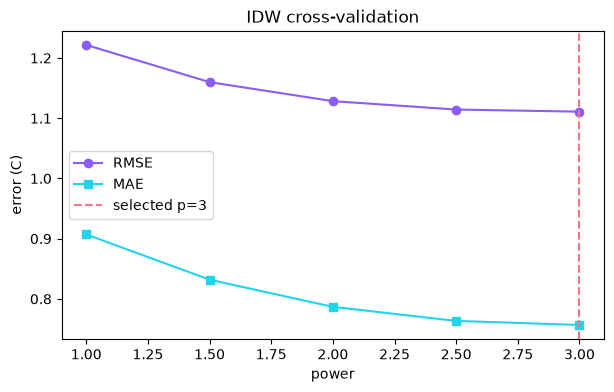

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(cv['power'], cv['rmse'], marker='o', label='RMSE', color='#8b5cf6')
ax.plot(cv['power'], cv['mae'], marker='s', label='MAE', color='#22d3ee')
best = cv.loc[cv['is_selected'] == 1, 'power'].iloc[0]
ax.axvline(best, ls='--', color='#fb7185', label=f'selected p={best:g}')
ax.set_xlabel('power'); ax.set_ylabel('error (C)'); ax.legend()
ax.set_title('IDW cross-validation'); plt.show()

## IDW vs Ordinary Kriging

In [5]:
db_mod.read_table(engine, 'interpolation_comparison').round(4)

,method,parameter,rmse,mae,r2,is_best
0,IDW,p=3,1.1109,0.7567,0.8515,0
1,Kriging,spherical,0.8889,0.5939,0.9049,1


## Rebuild the comparison in-memory to inspect the variogram

In [6]:
from src.analysis import interpolation_compare as ic
from src.data import ingest, preprocess
from src.features import extract

raw = ingest.load_inputs(cfg)
prep = preprocess.preprocess(cfg, raw)
grid = extract.extract_grid_features(
    cfg, prep.grid, prep.buildings, raw.landcover_polygons,
    raw.ndvi_path, raw.landcover_path, prep.crs)
xy = np.column_stack([prep.samples.geometry.x, prep.samples.geometry.y])
z = prep.samples['temp_c'].to_numpy(dtype=float)
comp = ic.compare_methods(cfg, xy, z, grid, prep.crs, prep.grid_res_m)
print('best:', comp.best_method)
print('variogram:', comp.variogram)

best: Kriging
variogram: {'model': 'spherical', 'psill': 7.437600884338148, 'range': 1306.4120218480457, 'nugget': 1.3614890372025602e-11}


## The final surface

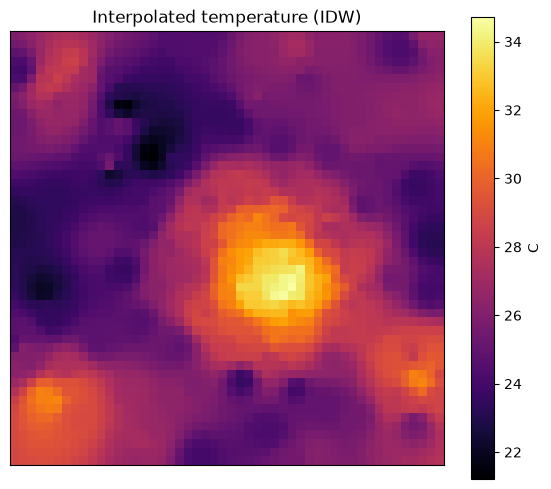

In [7]:
import rasterio
with rasterio.open(ROOT / 'outputs' / 'temperature_idw.tif') as src:
    surface = src.read(1)
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(surface, cmap='inferno')
ax.set_title('Interpolated temperature (IDW)'); ax.set_xticks([]); ax.set_yticks([])
plt.colorbar(im, label='C'); plt.show()

**Read this.** Kriging usually wins on a smooth field because it fits a variogram, while IDW is cheaper and needs no fitting. When the two are close, IDW is the sensible default.